In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Gradient Descent

Every model in this book was trained with a learning rate fixed before
the run, usually copied from a recipe and lowered if the loss diverged.
The previous section showed why the choice is delicate: on a valley that
curves steeply in one direction and gently in another, a step small enough
for the steep direction makes little progress along the gentle one. This
section asks what decides which learning rates work, and how fast the best
of them can go. We answer it for gradient descent, the simplest optimizer
and the ancestor of every other method in this chapter: compute the
gradient, take a step against it, and repeat.

Gradient descent has a single knob, the learning rate $\eta$, and on the
valley $f(\mathbf{x}) = 0.1 x_1^2 + 2 x_2^2$ of
that section this knob already decides everything. At
$\eta = 0.45$ the iterate needs 49 steps to come within 1% of the minimum,
at $\eta = 0.5$ it never arrives, and no learning rate does better than 47
steps. A learning rate that makes a large network diverge does so for the
same reason that it makes a one-dimensional quadratic diverge, so the small
cases are worth understanding completely.

We split the question into three. Why does a step against the gradient
lower the objective, and how large may the step be? What would the ideal
step be if we also knew the curvature? And how can we approximate that
ideal cheaply? The answers are a Taylor expansion, Newton's method, and
preconditioning. Preconditioning is the idea behind the adaptive methods of
that section. Throughout the section the gradient is exact;
that section replaces it with a noisy estimate.

## One-Dimensional Gradient Descent

Why should a step against the gradient reduce the objective at all? The
one-dimensional case already contains the answer. Let
$f: \mathbb{R} \rightarrow \mathbb{R}$ be continuously differentiable. For
a small change $\epsilon$ in its argument, its Taylor expansion reads

$$f(x + \epsilon) = f(x) + \epsilon f'(x) + O(\epsilon^2).$$

Near $x$ the function is close to its tangent line, so a move downhill
along the tangent should decrease $f$. We pick a step size $\eta > 0$, set
$\epsilon = -\eta f'(x)$, and substitute:

$$f(x - \eta f'(x)) = f(x) - \eta f'(x)^2 + O(\eta^2 f'(x)^2).$$

The first-order change $-\eta f'(x)^2$ is negative whenever the derivative
is not zero, and for small enough $\eta$ it outweighs the remainder.
Iterating the update

$$x \leftarrow x - \eta f'(x)$$

therefore decreases $f$ as long as the step is small. How small depends on
how fast the slope changes. If $f'$ is $L$-Lipschitz, that is, if the slope
changes by at most $L$ per unit of $x$, then every learning rate with
$0 < \eta < 2/L$ decreases $f$; that section proves this.

The quadratic $f(x) = x^2$ shows all of this in closed form. Its derivative
is $2x$, so one step maps $x$ to $x - 2\eta x$:

$$x \leftarrow (1 - 2\eta)\, x.$$

On a quadratic, gradient descent multiplies the distance to the minimum by
a fixed factor at every step. The iterates converge if and only if
$|1 - 2\eta| < 1$, that is, $0 < \eta < 1$, which is the bound $2/L$ with
$L = 2$. With $\eta = 0.2$ the factor is $0.6$, and ten steps from $x = 10$
should leave $10 \cdot 0.6^{10} \approx 0.06$. We check this numerically.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [ ]:
def f(x):  # Objective function
    return x ** 2

def f_grad(x):  # Its derivative
    return 2 * x

In [ ]:
def gd(eta, f_grad, steps=10):
    """Gradient descent from x = 10; returns all iterates."""
    x = 10.0
    results = [x]
    for _ in range(steps):
        x -= eta * f_grad(x)
        results.append(float(x))
    print(f'step {steps}, x: {float(x):f}')
    return results

results = gd(0.2, f_grad)

The iterates approach the minimum geometrically, each step keeping 60% of
the distance. We plot them on the graph of $f$.

In [ ]:
def show_trace(results, f):
    n = max(abs(min(results)), abs(max(results)))
    f_line = d2l.arange(-n, n, 0.01)
    d2l.set_figsize()
    d2l.plot([f_line, results], [f(f_line), [f(x) for x in results]],
             '$x$', '$f(x)$', fmts=['-', '-o'])

show_trace(results, f)

### Learning Rate

The learning rate is ours to choose, and the choice can go wrong in either
direction. With $\eta = 0.05$ the factor is $0.9$, and ten steps leave
$10 \cdot 0.9^{10} \approx 3.5$: the iterate barely moves, and reaching the
minimum would take many more steps.

epoch 10, x: 3.486784


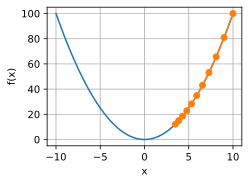

In [5]:
show_trace(gd(0.05, f_grad), f)

With $\eta = 1.1$ the factor is $-1.2$. Each step overshoots the minimum and
lands farther away on the other side, so after ten steps the distance has
grown to $10 \cdot 1.2^{10} \approx 62$. In the language of
the equation, the step $|\eta f'(x)|$ is too long for the tangent
line to be a good guide, and the remainder term takes over.

epoch 10, x: 61.917364


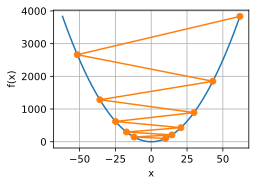

In [6]:
show_trace(gd(1.1, f_grad), f)

The best learning rate for this quadratic is $\eta = 0.5$: the factor is
zero, and a single step lands on the minimum. That rate is the inverse of
the curvature $f''(x) = 2$, an observation that returns with Newton's
method below.

### Local Minima

On a convex parabola the only risk is the step size. A nonconvex function
adds another: where the iterate ends up can depend on the learning rate.
Consider $f(x) = x \cos(cx)$ with $c = 0.15\pi$. From $x = 10$ the deep
basin around $x \approx 7.3$ is close by, and a shallow one lies near
$x \approx -1.8$. We run gradient descent with $\eta = 0.5$ and with
$\eta = 2$, and plot the second run.

In [ ]:
c = d2l.tensor(0.15 * np.pi)

def f_cos(x):  # Objective function
    return x * d2l.cos(c * x)

def f_cos_grad(x):  # Its derivative
    return d2l.cos(c * x) - c * x * d2l.sin(c * x)

gd(0.5, f_cos_grad)  # A moderate learning rate
show_trace(gd(2, f_cos_grad), f_cos)

With $\eta = 0.5$ the iterate rolls into the deep basin and stops near
$7.27$. With $\eta = 2$ the first step jumps over that basin to
$x \approx 0.6$, and the iterate ends up bouncing around the shallow
minimum. A learning rate this large is unrealistic for a one-dimensional
problem, but large steps in the early phase of training play the same role
in deep networks: they decide which region of the surface training
explores.

## Multivariate Gradient Descent

The same update works for a vector of parameters
$\mathbf{x} = (x_1, \ldots, x_d)$ and an objective
$f: \mathbb{R}^d \to \mathbb{R}$. The gradient collects the $d$ partial
derivatives,

$$\nabla f(\mathbf{x}) = \left(\frac{\partial f(\mathbf{x})}{\partial x_1}, \ldots, \frac{\partial f(\mathbf{x})}{\partial x_d}\right),$$

and each entry measures how fast $f$ changes when its coordinate alone
changes. The multivariate Taylor expansion has the same form as the
one-dimensional one,

$$f(\mathbf{x} + \boldsymbol{\epsilon}) = f(\mathbf{x}) + \boldsymbol{\epsilon}^\top \nabla f(\mathbf{x}) + O(\|\boldsymbol{\epsilon}\|^2).$$

Among all steps $\boldsymbol{\epsilon}$ of a fixed small length $r$, which
one decreases $f$ the most? To first order the change is
$\boldsymbol{\epsilon}^\top \nabla f(\mathbf{x})$, and by the
Cauchy–Schwarz inequality this inner product is at least
$-r \|\nabla f(\mathbf{x})\|$, with equality exactly when
$\boldsymbol{\epsilon}$ points along $-\nabla f(\mathbf{x})$. The negative
gradient is therefore the direction of *steepest descent*, and with a
learning rate $\eta > 0$ we obtain gradient descent:

$$\mathbf{x} \leftarrow \mathbf{x} - \eta \nabla f(\mathbf{x}).$$

We return to the valley, $f(\mathbf{x}) = 0.1 x_1^2 + 2 x_2^2$, with
curvatures $h_1 = 0.2$ along $x_1$ and $h_2 = 4$ along $x_2$. These are the
eigenvalues $\lambda_{\min}$ and $\lambda_{\max}$ of its Hessian in
that section, and the gradient is
$(h_1 x_1, h_2 x_2) = (0.2 x_1, 4 x_2)$. The rest of the chapter returns to
this valley, so we save it and its gradient.

In [ ]:
VALLEY_CURVATURES = (0.2, 4.0)
h1, h2 = VALLEY_CURVATURES  # Curvatures of the valley along x1 and x2

def f_valley(x1, x2):
    """The ill-conditioned quadratic valley h1/2 x1^2 + h2/2 x2^2, with
    (h1, h2) = VALLEY_CURVATURES."""
    h1, h2 = VALLEY_CURVATURES
    return h1 / 2 * x1 ** 2 + h2 / 2 * x2 ** 2

def valley_grad(x1, x2):
    """Gradient of f_valley."""
    h1, h2 = VALLEY_CURVATURES
    return h1 * x1, h2 * x2

To follow the iterates in the plane we write a helper that the rest of the
chapter reuses. `train_2d` starts at $(-5, -2)$ and applies an update rule
with the gradient `f_grad` for a given number of steps. Besides the two
coordinates and the gradient, the update rule receives and returns two
state variables, which the methods with memory in later sections
(momentum, Adam) use; gradient descent ignores them. Hyperparameters such
as the learning rate are passed through as keyword arguments. The plotting
utility `d2l.show_trace_2d` (that section) draws the path over the
contour lines of the objective.

In [ ]:
def train_2d(trainer, f_grad, steps=20, **hparams):
    """Run a 2D update rule from (-5, -2) and return the iterates."""
    x1, x2, s1, s2 = -5, -2, 0, 0  # s1, s2: state of stateful optimizers
    results = [(x1, x2)]
    for _ in range(steps):
        x1, x2, s1, s2 = trainer(x1, x2, s1, s2, f_grad, **hparams)
        results.append((x1, x2))
    print(f'step {steps}, x1: {float(x1):f}, x2: {float(x2):f}')
    return results

We run the same 30 steps at $\eta = 0.45$ as in
that section, now drawn in the plane.

In [ ]:
def gd_2d(x1, x2, s1, s2, f_grad, eta):
    """One step of gradient descent in 2D; the state stays zero."""
    g1, g2 = f_grad(x1, x2)
    return x1 - eta * g1, x2 - eta * g2, 0, 0

d2l.show_trace_2d(f_valley, train_2d(gd_2d, valley_grad, steps=30, eta=0.45))

Each step is perpendicular to the contour line through the current point,
as steepest descent must be. On a narrow valley that direction points
mostly across the valley: from $(-5, -2)$ the gradient is $(-1, -8)$, eight
times steeper across than along. The iterate therefore zigzags from wall
to wall and makes slow progress along the floor, and after 30 steps $x_1$
is still $-0.3$. A larger $\eta$ would speed up progress along the floor
but make the oscillation across the valley unstable. What the valley needs is a different learning rate in each
direction.

## Newton's Method

On the quadratic $x^2$ the best learning rate was the inverse of the
curvature. The valley has two curvatures, $0.2$ along $x_1$ and $4$ along
$x_2$, so a learning rate of $1/0.2 = 5$ along $x_1$ and $1/4$ along $x_2$
would solve each coordinate in a single step. Newton's method makes this
idea general: it measures the curvature in every direction and divides the
gradient by it.

The curvature enters through the second-order term of the Taylor
expansion,

$$f(\mathbf{x} + \boldsymbol{\epsilon}) = f(\mathbf{x}) + \boldsymbol{\epsilon}^\top \nabla f(\mathbf{x}) + \frac{1}{2} \boldsymbol{\epsilon}^\top \mathbf{H} \boldsymbol{\epsilon} + O(\|\boldsymbol{\epsilon}\|^3),$$

where $\mathbf{H} = \nabla^2 f(\mathbf{x})$ is the *Hessian*, the
$d \times d$ matrix of second derivatives. Ignoring the remainder, the
right-hand side is a quadratic in $\boldsymbol{\epsilon}$. Setting its
gradient with respect to $\boldsymbol{\epsilon}$ to zero (with the rules of
that section) gives the step that minimizes it:

$$\nabla f(\mathbf{x}) + \mathbf{H} \boldsymbol{\epsilon} = 0, \quad \textrm{hence} \quad \boldsymbol{\epsilon} = -\mathbf{H}^{-1} \nabla f(\mathbf{x}).$$

Newton's method is gradient descent with the gradient multiplied by the
inverse Hessian. Each direction receives the step its own curvature calls
for, and there is no learning rate to tune. When $f$ is itself a quadratic,
the expansion is exact and a single Newton step lands on the minimum. On
the valley, $\mathbf{H} = \textrm{diag}(0.2, 4)$ and
$\mathbf{H}^{-1} \nabla f(\mathbf{x}) = \mathbf{x}$, so one step from any
point reaches the origin, whatever the condition number.

On functions that are not quadratic, the method has to iterate. The convex
function $f(x) = \cosh(cx)$ with $c = 0.5$ has its minimum at $x = 0$, and
we run ten Newton steps from $x = 10$.

In [ ]:
def f_cosh(x, c=d2l.tensor(0.5)):  # Objective function
    return d2l.cosh(c * x)

def f_cosh_grad(x, c=d2l.tensor(0.5)):  # First derivative
    return c * d2l.sinh(c * x)

def f_cosh_hess(x, c=d2l.tensor(0.5)):  # Second derivative
    return c**2 * d2l.cosh(c * x)

def newton(f_grad, f_hess, eta=1, steps=10):
    """Newton's method from x = 10, with an optional step size eta."""
    x = 10.0
    results = [x]
    for _ in range(steps):
        x -= eta * f_grad(x) / f_hess(x)
        results.append(float(x))
    print(f'step {steps}, x: {float(x):f}')
    return results

show_trace(newton(f_cosh_grad, f_cosh_hess), f_cosh)

The iterate reaches the minimum to machine precision within ten steps, with
no learning rate chosen by hand.

Newton's method divides by the curvature, and the curvature of a nonconvex
function can be negative. Where it is, the step points uphill, toward a
maximum. We return to $f(x) = x \cos(cx)$ with $c = 0.15\pi$, which has a
minimum near $7.27$, close to the start.

In [ ]:
def f_cos_hess(x):  # Second derivative of f_cos
    return - 2 * c * d2l.sin(c * x) - x * c**2 * d2l.cos(c * x)

show_trace(newton(f_cos_grad, f_cos_hess), f_cos)

The first step overshoots to $x = 5$. The curvature there is positive but
small, so the next step divides a large slope by a small number and jumps
to $x \approx 25$, where the curvature is negative. From there the
iteration climbs to the local maximum near $26.8$, a point where the
gradient vanishes as it does at a minimum. One remedy is to
replace the Hessian by its absolute value, so that every step points
downhill. Another is to bring back a learning rate. With $\eta = 0.5$ the
first step stops at $x = 7.5$, inside the basin around the minimum, where
the curvature is positive, and the iteration converges. It converges only
linearly, however: each step halves the distance to $7.27$. Damping makes
the method safe here, and in exchange it gives up Newton's fast local rate.

In [ ]:
show_trace(newton(f_cos_grad, f_cos_hess, eta=0.5), f_cos)

Damping is no guarantee: it only makes a jump into a region of negative
curvature less likely. Two further facts about Newton's method matter
here, and the appendix proves both. First, near a minimum with positive
curvature it converges at least *quadratically*: the number of correct
digits roughly doubles with every step
(that section). Second, the method does not scale to
deep learning.

Storing the Hessian of a model with $d$ parameters takes
$O(d^2)$ memory and solving a linear system with it takes
$O(d^3)$ time. For $d = 10^9$ the Hessian has $10^{18}$ entries,
four exabytes in single precision, before the first step. And a deep
network's Hessian has negative eigenvalues, which steer the raw Newton step
toward saddles and maxima. Classical optimization lowers these costs with
curvature estimates built from successive gradients and with safer step
rules (that section). Deep learning keeps a simpler
part of the idea: rescale the gradient, direction by direction, with an
inexpensive estimate of the curvature.

## Preconditioning

A *preconditioner* rescales the gradient before the step. The simplest
useful one keeps only the diagonal of the Hessian,

$$\mathbf{x} \leftarrow \mathbf{x} - \eta \, \textrm{diag}(\mathbf{H})^{-1} \nabla f(\mathbf{x}),$$

which divides each coordinate of the gradient by the curvature along that
coordinate. In effect, every coordinate receives its own learning rate.
Storing the diagonal takes as much memory as storing the gradient.

Ill-conditioning of this axis-aligned kind arises from something as
mundane as units. Suppose a linear regression model receives two unrelated
length features of similar size, one recorded in meters and the other in
millimeters. The curvature of the squared loss along a weight is the mean
of the squared feature, so the millimeter weight has a curvature $10^6$
times larger than the meter weight. The units alone give a condition
number of at least $10^6$. A single learning rate small enough for the
millimeter weight leaves the meter weight almost frozen. Dividing by the diagonal curvature
removes the factor $10^6$ without our ever noticing the units.

On the valley, the diagonal of the Hessian is $(0.2, 4)$, and we run the
preconditioned update at $\eta = 0.5$.

In [ ]:
def precond_gd_2d(x1, x2, s1, s2, f_grad, eta):
    g1, g2 = f_grad(x1, x2)
    return x1 - eta * g1 / h1, x2 - eta * g2 / h2, 0, 0  # diag(H) = (h1, h2)

d2l.show_trace_2d(f_valley, train_2d(precond_gd_2d, valley_grad, steps=10,
                                     eta=0.5))

Both coordinates now shrink by the same factor $1 - \eta = 0.5$ per step,
so the path runs straight to the minimum. Seven steps bring both within 1%,
against 47 for the best plain learning rate, and the count no longer
depends on the condition number. At $\eta = 1$ one step suffices: because
the Hessian of the valley is diagonal, the diagonal preconditioner is
Newton's method.

Two limitations shape what comes next. A deep network does not give us its
Hessian, not even the diagonal, so practical methods estimate a diagonal
scale from the gradients they observe. AdaGrad, RMSProp, and Adam
(that section) differ mainly in how they form that estimate. And a
diagonal preconditioner only helps when the steep and flat directions line
up with the coordinate axes. Exercise 2
rotates the valley and shows the preconditioner failing. For this reason
later methods precondition whole weight matrices rather than single
coordinates.

With an exact gradient, then, the step size and the curvature explain
everything we have seen. But an exact gradient of a training loss requires
a pass over the whole dataset. The next section takes up this problem.

## Summary

Gradient descent decreases a differentiable function by stepping against
the gradient, and the decrease is guaranteed only while the step is short
enough for the first-order Taylor expansion to hold. On a quadratic each
step multiplies the error by a fixed factor: a learning rate that is too
small makes the factor close to one, and one that is too large makes it
exceed one in size and the iterates diverge. On nonconvex functions the
learning rate also decides which minimum the iterate reaches. Newton's
method divides the gradient by the curvature and solves a quadratic in one
step, whatever its condition number, but its cost and its attraction to
maxima and saddles rule it out for deep networks. Preconditioning keeps the
useful part: a diagonal rescaling solved the valley in seven steps instead
of 47, and the adaptive methods of later sections estimate such a rescaling
from gradients.

## Exercises

1. [code] **Learning-rate sweep.** Extend `gd` to run at most 100 steps
   and to stop as soon as $|x| < 10^{-3}$. Run it on $f(x) = x^2$,
   $f(x) = |x|^{1.5}$, and $f(x) = x^4$ at
   $\eta \in \{0.01, 0.1, 0.5, 0.9, 1.1\}$.
    1. Tabulate, for each of the fifteen runs, the number of steps until
       the stopping test holds, or, for a run that misses the test within
       100 steps, whether $|x|$ grew without bound or stayed bounded.
    1. The second derivative of $|x|^{1.5}$ is unbounded near the origin.
       Explain what the iterates do close to $0$ at any fixed $\eta$, and
       why the stopping test is reached late or not at all.
    1. The second derivative of $x^4$ vanishes at the origin. Show that
       once the iterates are small, $x_{t+1} \approx x_t (1 - 4\eta x_t^2)$,
       and that $|x_t|$ then decays like $1/\sqrt{8 \eta t}$ rather than
       geometrically. Why can no fixed learning rate restore a geometric
       rate on this function?

1. [code] **Diagonal preconditioning under rotation.** Rotate the valley
   by an angle $\theta$: $f_\theta(\mathbf{x}) = \frac{1}{2}
   \mathbf{x}^\top \mathbf{R}_\theta \textrm{diag}(0.2, 4)
   \mathbf{R}_\theta^\top \mathbf{x}$, where $\mathbf{R}_\theta$ is the
   rotation matrix by $\theta$.
    1. For $\theta = 45^\circ$, run plain gradient descent at
       $\eta = 0.45$, the diagonal preconditioner
       the equation at $\eta = 0.5$, and Newton's method
       with `d2l.train_2d`. Which of the three behave as on the unrotated
       valley? Explain the behavior of the diagonal preconditioner from
       the entries of the rotated Hessian.
    1. The preconditioned update behaves like plain gradient descent on a
       quadratic with Hessian
       $\mathbf{D}^{-1/2} \mathbf{H}_\theta \mathbf{D}^{-1/2}$, where
       $\mathbf{D} = \textrm{diag}(\mathbf{H}_\theta)$. Compute its
       condition number as a function of $\theta$, and check that it is $1$
       at $\theta = 0$ and $20$ at $\theta = 45^\circ$.
    1. A deep network's Hessian is not diagonal in its parameter
       coordinates. What does this exercise suggest about how much a
       diagonal preconditioner can help, and what would a preconditioner
       need in order to undo a rotation?

1. [code] **Absolute-curvature preconditioning.** Replace
   $\textrm{diag}(\mathbf{H})^{-1}$ in the equation by
   $|\textrm{diag}(\mathbf{H})|^{-1}$ and run this variant at $\eta = 1$ on
   the nonconvex $f(x_1, x_2) = x_1 \cos(c x_1) + x_2 \cos(c x_2)$ with
   $c = 0.15\pi$ from the starting point of `d2l.train_2d`. Show that every
   update direction is a descent direction. Does every step decrease $f$?
   Explain the size of the largest step of the run.

1. **Certifying the lowest minimum.** ● Modify the objective
   $f(x) = x\cos(cx)$ with $c = 0.15\pi$ of that section
   so that its local minima in $(-20, 20)$ differ in value by at most
   $10^{-3}$ except for one. Explain why any method that uses only $f$ and
   $f'$ at the points it visits must then visit every basin before it can
   certify which local minimum is lowest.

1. [code] **Newton's convergence order.** ● In that section,
   `newton` converges in a few steps on $f(x) = \cosh(cx)$. Run it with
   $c = 0.5$ from $x_0 = 10$ and record $|x_t|$ after every step.
    1. From the last steps before $x_t$ reaches $0$ in floating point,
       estimate the order $p$ in $|x_{t+1}| \approx C |x_t|^p$. Where does
       this fast phase begin, and what governs the steps before it?
    1. Derive $p$ and $C$ from the Taylor expansion of the update
       $x - \tanh(cx)/c$ around $0$, and reconcile $p$ with the quadratic
       rate stated in that section.

1. [code] **Stale Hessian factorizations.** ● A Newton step in $d$
   dimensions can reuse the Hessian factorization of an earlier step.
   Minimize
   $f(\mathbf{x}) = \sum_{i=1}^{n} \cosh(c\, \mathbf{a}_i^\top \mathbf{x})$
   with $n = 200$, $d = 50$, $c = 0.5$, directions $\mathbf{a}_i$ with
   independent standard Gaussian entries, and $\mathbf{x}_0 = \mathbf{1}$.
   Its minimum is $f^\star = n$ at $\mathbf{x} = \mathbf{0}$. Charge $4nd$
   operations per gradient, $nd^2$ per Hessian evaluation, $d^3/3$ per
   Cholesky factorization, and $2d^2$ per pair of triangular solves.
   Evaluate and factor the Hessian on every step, every 5 steps, and every
   20 steps, reusing the stale factorization in between. Plot
   $f(\mathbf{x}_t) - f^\star$ against the cumulative operation count
   rather than the iteration count. Which variant reaches $10^{-8}$ first,
   and which of the four costs dominates its total?

    *Adapted from Stephen Boyd and Lieven Vandenberghe,
    [Convex Optimization](https://web.stanford.edu/~boyd/cvxbook/),
    Exercise 9.31(a).*

[Discussions](https://d2l.discourse.group/t/351)